# Usage stabilization: how long before a customer's pattern settles?

The goal of the next notebook is to find customers who **started** using a technology part-way through the year, for example by buying an EV or installing a heat pump. To tell a real, lasting change from ordinary ups and downs, we first need to know:

1. **How many days of data it takes to pin down a customer's usage pattern.** A pattern measured over 2 days is mostly noise; one measured over several weeks is more reliable.
2. **How much a customer's pattern normally drifts** from one period to the next when nothing has changed.

The answers set the rules for flagging changes: how long a new pattern must last before it counts, and how big a shift has to be.

### Removing weather and seasonality

We have only **one year** of data, so we can't compare a customer's January with last January. Higher winter use could be a new heat pump or simply winter. Instead, each customer is compared with **similar customers on the same days**. Weather, season, holidays and daylight-saving changes affect everyone in a peer group at once, so they cancel out when we look at how a customer differs from their peers.

This notebook:

1. Groups customers into **peer groups** with similar usage shape, size and temperature response.
2. Expresses each customer's hourly use **relative to their peer group** on the same date and hour.
3. Measures how **similar a customer's pattern is between two windows** (the correlation, R) as the windows get longer, to find where it levels off.
4. Compares this with a **per-customer weather model**, as a cross-check.
5. Saves the results to DuckDB for notebook 60.

Run from the project folder after notebooks 10–40. Several steps hold a large array (about 1 GB) in memory.

## Setup

`OMP_NUM_THREADS` is set to 1 before scikit-learn is imported, for the reason explained in notebook 40: scikit-learn otherwise slows down badly on this machine.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'  # must be set before importing scikit-learn

import math
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', message='Mean of empty slice')
warnings.filterwarnings('ignore', message='Degrees of freedom')
warnings.filterwarnings('ignore', category=RuntimeWarning, message='invalid value encountered')

DB_PATH = 'onedrive-export/Data/avangrid.db'
CUSTOMER_GROUPS_PATH = 'onedrive-export/Data/EV_Heat Pump_Solar PV Customers.xlsx'
PLOT_DIR = 'onedrive-export/Data/eda'

con = duckdb.connect(DB_PATH)
con.execute('SET enable_progress_bar = false')

## 1. Peer groups

### Which customers are included

All customers in `ami_analysis` except the **188 who average under 0.05 kWh per hour**. Their use is so close to zero that relative changes are meaningless, and dividing by their average would blow up tiny fluctuations.

### What makes two customers "peers"

Peers should react to weather, seasons and the calendar in the same way, so that comparing a customer with their peers removes those effects. Customers are grouped on:

- **Daily shape**: average use at each hour of the day, separately for weekdays and weekends (48 values), each divided by the customer's overall average. This captures *when* a home uses electricity, regardless of how much.
- **Size**: the log of average hourly use.
- **Temperature response**: heating and cooling slopes relative to mild-day use, and the log winter-to-summer ratio, all from `customer_features` (notebook 40).

The temperature features matter. A home with electric heating has a winter rise that a gas-heated home doesn't. If they were peers, every electrically heated home would look like it "changed" each winter.

Extreme values are capped at the 1st and 99th percentiles so a few unusual customers don't dominate, and all features are standardized. The 4 size and temperature features are given extra weight so they aren't swamped by the 48 shape values.

**k-means with 16 groups** was chosen so that even the smallest group has several hundred customers (about 700). Each group's hourly average is then stable enough to serve as the benchmark.

### Using the full year

Groups are based on the **whole year**, including any period after a customer adopted a technology. A customer who adopted mid-year may land in a group that partly reflects their new pattern. The change still shows up as a shift *relative to* the group (below it before, above it after), which is what notebook 60 looks for.

In [2]:
MIN_MEAN_KWH = 0.05
N_PEER_GROUPS = 16

shape = con.sql(f'''
    WITH m AS (
        SELECT CUSTOMER_NUMBER, AVG(hourly_kwh) AS mean_kwh
        FROM ami_analysis WHERE NOT is_imputed GROUP BY 1
    )
    SELECT a.CUSTOMER_NUMBER, a.day_type, a.hour_ending,
           AVG(a.hourly_kwh / m.mean_kwh) AS n
    FROM ami_analysis a JOIN m USING (CUSTOMER_NUMBER)
    WHERE NOT a.is_imputed AND m.mean_kwh >= {MIN_MEAN_KWH}
    GROUP BY ALL
''').pl()

shape_wide = (
    shape.with_columns((pl.col('day_type').cast(pl.String) + '_' + pl.col('hour_ending').cast(pl.String)).alias('k'))
    .pivot(on='k', index='CUSTOMER_NUMBER', values='n')
)
extra = con.sql(f'''
    SELECT CUSTOMER_NUMBER, ln(mean_kwh) AS log_mean_kwh, heating_slope_rel, cooling_slope_rel,
           ln(winter_summer_ratio) AS log_winter_summer
    FROM customer_features WHERE mean_kwh >= {MIN_MEAN_KWH}
''').pl()
peer_input = shape_wide.join(extra, on='CUSTOMER_NUMBER').sort('CUSTOMER_NUMBER')

X = peer_input.drop('CUSTOMER_NUMBER').to_numpy().astype(float)
X[~np.isfinite(X)] = np.nan
X = np.where(np.isnan(X), np.nanmedian(X, axis=0), X)
X = np.clip(X, np.percentile(X, 1, axis=0), np.percentile(X, 99, axis=0))
Z = StandardScaler().fit_transform(X)
weights = np.ones(Z.shape[1])
weights[-4:] = math.sqrt(48 / 4 / 2)   # give the 4 size/temperature features about half the total weight of the 48 shape values
Z *= weights

kmeans = KMeans(N_PEER_GROUPS, n_init=10, random_state=0).fit(Z)
peer_groups = peer_input.select('CUSTOMER_NUMBER').with_columns(
    pl.Series('peer_group', kmeans.labels_.astype(np.int16))
)

con.register('peer_groups_df', peer_groups)
con.execute('''
    CREATE OR REPLACE TABLE customer_peer_groups AS
    SELECT p.CUSTOMER_NUMBER, p.peer_group, m.mean_kwh_real
    FROM peer_groups_df p
    JOIN (SELECT CUSTOMER_NUMBER, AVG(hourly_kwh) AS mean_kwh_real
          FROM ami_analysis WHERE NOT is_imputed GROUP BY 1) m USING (CUSTOMER_NUMBER)
    ORDER BY CUSTOMER_NUMBER
''')
print(f'{peer_groups.height:,} customers in {N_PEER_GROUPS} peer groups')
print('Customers per peer group:', dict(peer_groups.group_by('peer_group').len().sort('peer_group').iter_rows()))

33,310 customers in 16 peer groups
Customers per peer group: {0: 1657, 1: 1365, 2: 1841, 3: 3157, 4: 3038, 5: 2289, 6: 3049, 7: 1555, 8: 969, 9: 2652, 10: 1205, 11: 1961, 12: 1663, 13: 1576, 14: 1571, 15: 3762}


### What the peer groups look like

Each panel shows a group's average weekday shape (use at each hour divided by the customer's average, so 1.0 means an average hour), with the share of the group's customers on the EV, HP and PV lists. The groups differ mainly in *when* use peaks: early-evening peaks, late-evening peaks, flat profiles, a morning-and-evening pattern, and a deep midday dip. The midday-dip group contains a much higher share of PV customers than any other, and the late-evening-peak groups contain the most EV customers. Both are what you'd expect from solar generation and overnight charging.

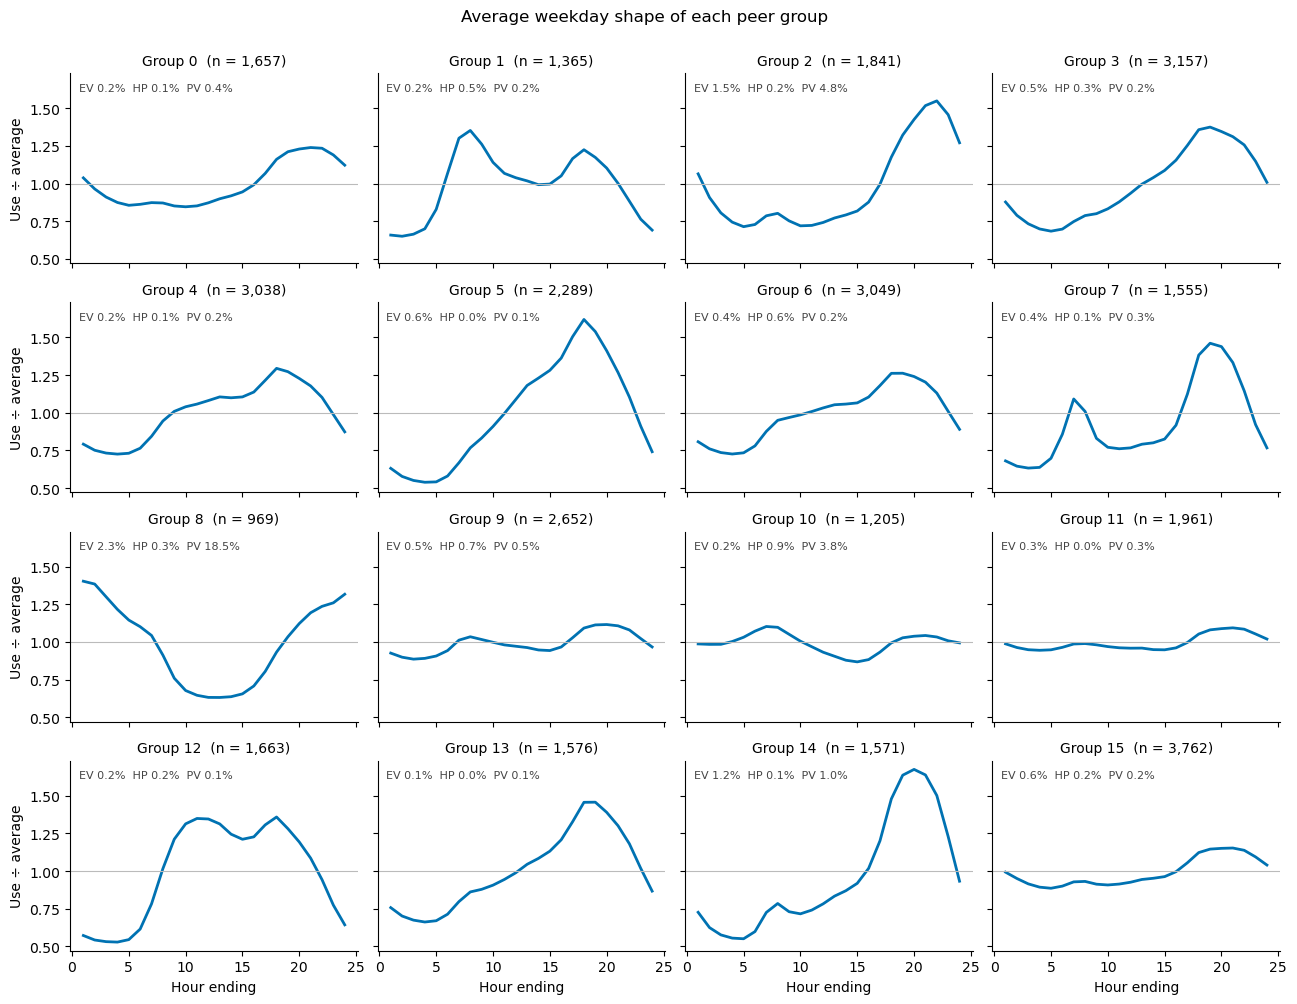

In [3]:
sheets = pl.read_excel(CUSTOMER_GROUPS_PATH, sheet_id=0)
sheets.pop('Description')
labels = peer_groups
for tab, customers in sheets.items():
    labels = labels.with_columns(
        pl.col('CUSTOMER_NUMBER').is_in(customers['CUSTOMER_NUMBER'].cast(pl.Int32).implode()).alias(tab.split()[0])
    )
group_mix = labels.group_by('peer_group').agg(pl.len().alias('n'), pl.col('EV').mean(), pl.col('HP').mean(), pl.col('PV').mean())

weekday = (shape.filter(pl.col('day_type') == 'Weekday')
           .join(peer_groups, on='CUSTOMER_NUMBER')
           .group_by('peer_group', 'hour_ending').agg(pl.col('n').mean())
           .sort('peer_group', 'hour_ending'))

fig, axes = plt.subplots(4, 4, figsize=(13, 10), sharex=True, sharey=True)
for g, ax in zip(range(N_PEER_GROUPS), axes.flat):
    p = weekday.filter(pl.col('peer_group') == g)
    mix = group_mix.filter(pl.col('peer_group') == g).row(0, named=True)
    ax.plot(p['hour_ending'], p['n'], color='#0072B2', linewidth=2)
    ax.axhline(1, color='#bbbbbb', linewidth=0.8)
    ax.set_title(f"Group {g}  (n = {mix['n']:,})", fontsize=10)
    ax.text(0.03, 0.95, f"EV {mix['EV']:.1%}  HP {mix['HP']:.1%}  PV {mix['PV']:.1%}",
            transform=ax.transAxes, fontsize=8, va='top', color='#444444')
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel('Hour ending')
for ax in axes[:, 0]:
    ax.set_ylabel('Use ÷ average')
fig.suptitle('Average weekday shape of each peer group', y=1.0)
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/peer_group_profiles.png', dpi=150)
plt.show()

## 2. Usage relative to peers

For every hour, each customer's use is turned into a **peer-relative residual**:

1. **Normalize**: divide the customer's use by their own average hourly use (real readings only). A value of 1.0 means a typical hour for that customer, so large and small homes can be compared.
2. **Peer index**: for each peer group, date and hour, average the normalized use of all customers in the group. This is what a typical member of the group did at that moment, given that day's weather, season and day of the week.
3. **Residual** = normalized use − peer index. Zero means the customer behaved like their peers. Positive means more than usual relative to peers; negative means less.

**Imputed hours** (from notebook 20) are left out of the peer index and set to missing in the residuals. They were filled with averages from the same week, so including them would make a customer look more consistent than they really are.

The peer index is saved to DuckDB as **`peer_index`** (group × date × hour, about 140,000 rows). Notebook 60 can then recreate residuals without repeating this step.

The residuals are loaded into a NumPy array of **customers × days × hours** (about 25,000 × 365 × 24, roughly 0.9 GB). That makes the window calculations below fast. The hour that doesn't exist when clocks go forward (2026-03-08) is left missing.

In [4]:
con.execute('''
    CREATE OR REPLACE TEMP TABLE normalized AS
    SELECT a.CUSTOMER_NUMBER, g.peer_group, a.usage_date, a.hour_ending, a.is_imputed,
           a.hourly_kwh / g.mean_kwh_real AS n
    FROM ami_analysis a JOIN customer_peer_groups g USING (CUSTOMER_NUMBER)
''')
con.execute('''
    CREATE OR REPLACE TABLE peer_index AS
    SELECT peer_group, usage_date, hour_ending, AVG(n) AS peer_n, COUNT(*) AS customers
    FROM normalized WHERE NOT is_imputed
    GROUP BY ALL ORDER BY ALL
''')

customers = con.sql('SELECT CUSTOMER_NUMBER, peer_group FROM customer_peer_groups ORDER BY 1').pl()
slots = con.sql('SELECT DISTINCT usage_date, hour_ending FROM normalized ORDER BY 1, 2').pl()
start_date = slots['usage_date'].min()
slot_day = (slots['usage_date'] - start_date).dt.total_days().to_numpy()
slot_hour = slots['hour_ending'].to_numpy() - 1
N_DAYS = int(slot_day.max()) + 1
dates = pl.date_range(start_date, slots['usage_date'].max(), eager=True)

residual_values = con.sql('''
    SELECT CASE WHEN n.is_imputed THEN NULL ELSE n.n - p.peer_n END::FLOAT AS e
    FROM normalized n JOIN peer_index p USING (peer_group, usage_date, hour_ending)
    ORDER BY n.CUSTOMER_NUMBER, n.usage_date, n.hour_ending
''').pl()['e'].to_numpy()

N_CUST = customers.height
assert residual_values.size == N_CUST * slots.height, 'every customer should have one row per slot'

E = np.full((N_CUST, N_DAYS, 24), np.nan, dtype=np.float32)       # peer-relative residuals
E[:, slot_day, slot_hour] = residual_values.reshape(N_CUST, slots.height)
del residual_values

# Peer index as an array (group x day x hour), used to rebuild raw normalized use when needed
pidx = con.sql('SELECT peer_group, usage_date, hour_ending, peer_n FROM peer_index').pl()
P = np.full((N_PEER_GROUPS, N_DAYS, 24), np.nan, dtype=np.float32)
P[pidx['peer_group'].to_numpy(),
  (pidx['usage_date'] - start_date).dt.total_days().to_numpy(),
  pidx['hour_ending'].to_numpy() - 1] = pidx['peer_n'].to_numpy()
group_of = customers['peer_group'].to_numpy()

print(f'Residual array: {E.shape} ({E.nbytes / 1e9:.2f} GB), {np.isnan(E).mean():.2%} missing (imputed or non-existent hours)')

Residual array: (33310, 365, 24) (1.17 GB), 0.12% missing (imputed or non-existent hours)


## 3. How similar is a customer's pattern between two windows?

A customer's **pattern** for a window of L days is their average residual at each of the 24 hours of the day, averaged over the days in the window. We measure how alike two patterns are with the **correlation R** between the two 24-hour profiles. R near 1 means the same shape (for example, always above peers in the evening and below them at midday); R near 0 means no shared shape.

Weekdays and weekends are combined. Comparing with peers already removes the weekday/weekend difference that customers share, and keeping them apart would leave too few days in short windows.

Three comparisons, each for window lengths from 1 to 56 days:

- **Interleaved windows**: split a 2L-day period into odd and even days, giving two L-day windows from the **same** period. Any difference between them is noise, not change. This shows how quickly a pattern can be measured when nothing is changing.
- **Adjacent windows**: compare L days with the **next** L days. Differences now include real drift over time as well as noise.
- **Different customers**: compare one customer's window with a *different* customer's next window. This is the baseline: the R you'd get from patterns that are unrelated.

Windows start every 14 days through the year. For each customer, R is averaged over the start dates, and the chart shows the median across customers.

We do the same with **raw normalized use** (not relative to peers), to show why removing shared patterns matters.

In [5]:
def row_corr(A, B):
    """Pearson correlation between matching rows of A and B, ignoring missing values."""
    A = A - np.nanmean(A, axis=1, keepdims=True)
    B = B - np.nanmean(B, axis=1, keepdims=True)
    return np.nansum(A * B, axis=1) / np.sqrt(np.nansum(A * A, axis=1) * np.nansum(B * B, axis=1))


WINDOW_LENGTHS = [1, 2, 3, 5, 7, 10, 14, 21, 24, 28, 31, 35, 42, 56]
ANCHOR_STEP = 14
other = np.random.default_rng(0).permutation(N_CUST)

curves = []
adjacent_by_customer = {}
interleaved_by_customer = {}
for L in WINDOW_LENGTHS:
    anchors = range(0, N_DAYS - 2 * L + 1, ANCHOR_STEP)
    r = {k: [] for k in ['interleaved', 'adjacent', 'different', 'raw_interleaved', 'raw_adjacent', 'raw_different']}
    for a in anchors:
        resid = E[:, a:a + 2 * L]
        raw = resid + P[group_of, a:a + 2 * L]     # normalized use = residual + peer index
        for prefix, block in [('', resid), ('raw_', raw)]:
            first, second = np.nanmean(block[:, :L], axis=1), np.nanmean(block[:, L:], axis=1)
            odd, even = np.nanmean(block[:, 0::2], axis=1), np.nanmean(block[:, 1::2], axis=1)
            r[prefix + 'interleaved'].append(row_corr(odd, even))
            r[prefix + 'adjacent'].append(row_corr(first, second))
            r[prefix + 'different'].append(row_corr(first, second[other]))
    per_customer = {k: np.nanmean(np.array(v), axis=0) for k, v in r.items()}
    adjacent_by_customer[L] = per_customer['adjacent']
    interleaved_by_customer[L] = per_customer['interleaved']
    curves.append({'window_days': L, 'anchors': len(anchors)} |
                  {k: float(np.nanmedian(v)) for k, v in per_customer.items()})

curves = pl.DataFrame(curves)
with pl.Config(tbl_rows=-1, float_precision=3, tbl_hide_dataframe_shape=True):
    print(curves)

┌─────────────┬─────────┬────────────┬──────────┬───────────┬────────────┬────────────┬────────────┐
│ window_days ┆ anchors ┆ interleave ┆ adjacent ┆ different ┆ raw_interl ┆ raw_adjace ┆ raw_differ │
│ ---         ┆ ---     ┆ d          ┆ ---      ┆ ---       ┆ eaved      ┆ nt         ┆ ent        │
│ i64         ┆ i64     ┆ ---        ┆ f64      ┆ f64       ┆ ---        ┆ ---        ┆ ---        │
│             ┆         ┆ f64        ┆          ┆           ┆ f64        ┆ f64        ┆ f64        │
╞═════════════╪═════════╪════════════╪══════════╪═══════════╪════════════╪════════════╪════════════╡
│ 1           ┆ 26      ┆ 0.244      ┆ 0.244    ┆ 0.009     ┆ 0.298      ┆ 0.298      ┆ 0.078      │
│ 2           ┆ 26      ┆ 0.333      ┆ 0.319    ┆ 0.005     ┆ 0.420      ┆ 0.405      ┆ 0.113      │
│ 3           ┆ 26      ┆ 0.358      ┆ 0.333    ┆ 0.005     ┆ 0.463      ┆ 0.442      ┆ 0.135      │
│ 5           ┆ 26      ┆ 0.453      ┆ 0.413    ┆ 0.003     ┆ 0.580      ┆ 0.547      ┆ 0.1

### Where the pattern stabilizes

The **adjacent-window** curve is the one that matters for spotting change. It rises as longer windows average out day-to-day noise. Beyond a certain length it **stops rising and starts to fall**, because the two windows are then far enough apart that real drift over time outweighs the extra data.

We define the **stabilization length** as the **shortest window whose adjacent-window R is within 0.01 of the curve's peak**: the point where it levels off. For the weekly calculations in notebook 60, this is rounded up to whole weeks.

Adjacent-window R peaks at 0.634 with 35-day windows.
Stabilization length (within 0.01 of the peak): 24 days -> 4 weeks for weekly analysis.


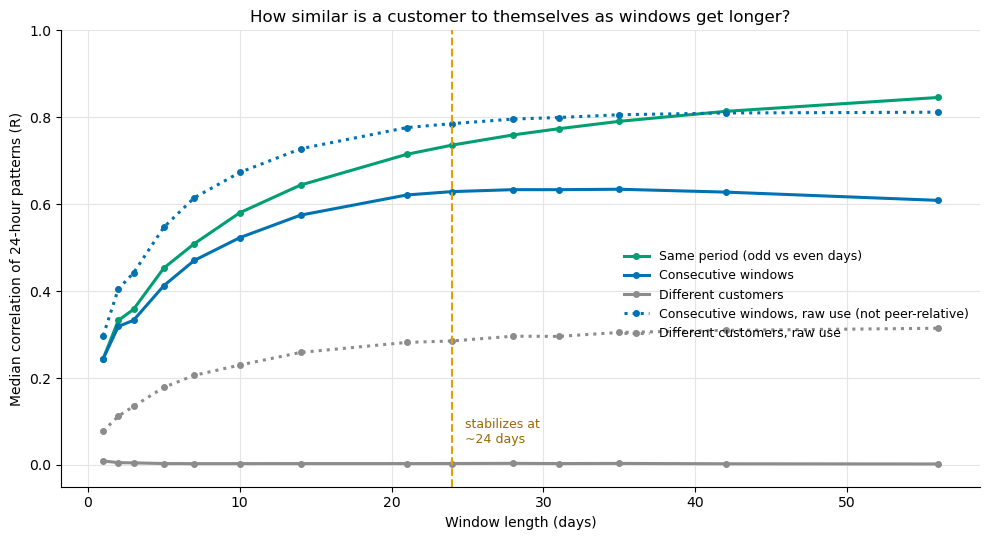

In [6]:
peak_r = curves['adjacent'].max()
STABILIZATION_DAYS = int(curves.filter(pl.col('adjacent') >= peak_r - 0.01)['window_days'].min())
STABILIZATION_WEEKS = math.ceil(STABILIZATION_DAYS / 7)
peak_days = int(curves.filter(pl.col('adjacent') == peak_r)['window_days'].item())

print(f'Adjacent-window R peaks at {peak_r:.3f} with {peak_days}-day windows.')
print(f'Stabilization length (within 0.01 of the peak): {STABILIZATION_DAYS} days '
      f'-> {STABILIZATION_WEEKS} weeks for weekly analysis.')

fig, ax = plt.subplots(figsize=(10, 5.5))
styles = [('interleaved', 'Same period (odd vs even days)', '#009E73', '-'),
          ('adjacent', 'Consecutive windows', '#0072B2', '-'),
          ('different', 'Different customers', '#8c8c8c', '-'),
          ('raw_adjacent', 'Consecutive windows, raw use (not peer-relative)', '#0072B2', ':'),
          ('raw_different', 'Different customers, raw use', '#8c8c8c', ':')]
for col, label, color, ls in styles:
    ax.plot(curves['window_days'], curves[col], color=color, linestyle=ls, linewidth=2.2, marker='o', markersize=4, label=label)
ax.axvline(STABILIZATION_DAYS, color='#E69F00', linewidth=1.5, linestyle='--')
ax.text(STABILIZATION_DAYS + 0.8, 0.05, f'stabilizes at\n~{STABILIZATION_DAYS} days', color='#9a6700', fontsize=9)
ax.set_xlabel('Window length (days)')
ax.set_ylabel('Median correlation of 24-hour patterns (R)')
ax.set_title('How similar is a customer to themselves as windows get longer?')
ax.set_ylim(-0.05, 1)
ax.grid(color='#e5e5e5', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='center right', bbox_to_anchor=(1.0, 0.42), fontsize=9)
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/stabilization_curves.png', dpi=150)
plt.show()

### Reading the curves

- **Raw use overstates stability.** With raw normalized use (dotted lines), even two *different* customers' patterns correlate at about 0.3, because nearly everyone uses more in the evening than overnight. Part of a customer's raw R is therefore just the shared daily cycle. Raw consecutive-window R also keeps climbing with window length, which hides the drift visible in the peer-relative curve. Relative to peers, different customers correlate at about 0, so R measures only what is specific to each customer.
- **Patterns take weeks to settle.** A single day's pattern is a poor guide to the next day (R about 0.25). Agreement rises steadily as days are averaged.
- **The same-period curve keeps rising, but the consecutive-window curve levels off** at the stabilization length and then dips. The growing gap between them is genuine drift: customers' habits shift gradually over weeks, even without a new technology.
- **Even at its best, consecutive-window R is moderate (about 0.6).** Most customers' behaviour shifts noticeably month to month. A new EV or heat pump therefore has to cause a *larger and longer-lasting* shift than this normal drift to be detectable.

### Does combining weekdays and weekends affect this?

Each window above combines weekdays and weekends into one 24-hour profile. Comparing with peers removes weekend effects that customers **share** (for example, everyone getting up later on Saturday), because each day is compared with the peer group on that same day. It does **not** remove a customer's **own** weekend habits, such as being home on weekends when their peers aren't. Window lengths that aren't whole weeks (24 or 31 days, say) can also contain one more or one fewer weekend day than the window they're compared with.

To check whether combining days changes the result, we repeat the consecutive-window comparison using **weekdays only** and **weekends only**. We also record how many weekend days each window holds, and how similar each customer's weekday and weekend profiles (relative to peers) are over the whole year.

In [7]:
is_weekend = (dates.dt.weekday() >= 6).to_numpy()   # polars weekday: Monday = 1, Sunday = 7

day_type_curves = []
for L in [7, 10, 14, 21, 24, 28, 31, 35, 42, 56]:
    r = {'all_days': [], 'weekdays_only': [], 'weekends_only': []}
    weekend_counts = set()
    for a in range(0, N_DAYS - 2 * L + 1, ANCHOR_STEP):
        block, wk = E[:, a:a + 2 * L], is_weekend[a:a + 2 * L]
        first, second = block[:, :L], block[:, L:]
        wk1, wk2 = wk[:L], wk[L:]
        weekend_counts.update({int(wk1.sum()), int(wk2.sum())})
        r['all_days'].append(row_corr(np.nanmean(first, axis=1), np.nanmean(second, axis=1)))
        for name, k1, k2 in [('weekdays_only', ~wk1, ~wk2), ('weekends_only', wk1, wk2)]:
            if k1.any() and k2.any():
                r[name].append(row_corr(np.nanmean(first[:, k1], axis=1), np.nanmean(second[:, k2], axis=1)))
    day_type_curves.append({'window_days': L,
                            'weekend_days_per_window': ', '.join(map(str, sorted(weekend_counts)))} |
                           {k: float(np.nanmedian(np.nanmean(np.array(v), axis=0))) for k, v in r.items()})
day_type_curves = pl.DataFrame(day_type_curves)

weekday_peak = day_type_curves['weekdays_only'].max()
weekday_stabilization = int(day_type_curves.filter(pl.col('weekdays_only') >= weekday_peak - 0.01)['window_days'].min())
weekday_profile = np.nanmean(E[:, ~is_weekend], axis=1)
weekend_profile = np.nanmean(E[:, is_weekend], axis=1)
weekday_weekend_r = float(np.nanmedian(row_corr(weekday_profile, weekend_profile)))

with pl.Config(tbl_rows=-1, float_precision=3, tbl_hide_dataframe_shape=True):
    print(day_type_curves)
print(f'\nWeekdays only: stabilizes at {weekday_stabilization} days (same rule: within 0.01 of the peak).')
print(f'Median R between a customer\'s weekday and weekend profiles over the year: {weekday_weekend_r:.2f}')

┌─────────────┬─────────────────────────┬──────────┬───────────────┬───────────────┐
│ window_days ┆ weekend_days_per_window ┆ all_days ┆ weekdays_only ┆ weekends_only │
│ ---         ┆ ---                     ┆ ---      ┆ ---           ┆ ---           │
│ i64         ┆ str                     ┆ f64      ┆ f64           ┆ f64           │
╞═════════════╪═════════════════════════╪══════════╪═══════════════╪═══════════════╡
│ 7           ┆ 2                       ┆ 0.471    ┆ 0.447         ┆ 0.238         │
│ 10          ┆ 2, 3                    ┆ 0.523    ┆ 0.508         ┆ 0.257         │
│ 14          ┆ 4                       ┆ 0.575    ┆ 0.550         ┆ 0.337         │
│ 21          ┆ 6                       ┆ 0.621    ┆ 0.601         ┆ 0.387         │
│ 24          ┆ 6, 7                    ┆ 0.629    ┆ 0.612         ┆ 0.393         │
│ 28          ┆ 8                       ┆ 0.633    ┆ 0.618         ┆ 0.422         │
│ 31          ┆ 8, 9                    ┆ 0.633    ┆ 0.621       

- **Weekdays on their own give the same stabilization length.** The weekday-only curve levels off at the same point and stays flat for several weeks, so the result isn't caused by combining day types.
- **Combining days doesn't hurt.** The all-days curve is slightly *higher* than weekdays only, because the extra days reduce noise more than the mix of day types adds. Each customer's weekday and weekend profiles are fairly similar (median R shown above), so combining them is reasonable.
- **Uneven weekend counts make no visible difference.** Windows whose lengths aren't whole weeks (24, 31 days) sit in line with whole-week windows (21, 28, 35 days).
- **Weekend-only patterns are much noisier** and are still rising at 56 days, which contains only 16 weekend days. Weekend-only analysis needs roughly twice as long to settle. Notebook 60 keeps weekdays and weekends combined, and should only look at weekends separately if a technology mainly shows up on weekends.

## 4. Differences between customers

Customers differ in how regular they are. For each customer we record:

- **`pattern_r`**: same-period (interleaved) R at the stabilization length. How reliably their pattern can be measured. Customers with a weak, noisy pattern are hard to monitor for changes.
- **`consecutive_r`**: consecutive-window R at the stabilization length. How much their pattern normally drifts.
- **`peak_window_days`**: the window length at which *their own* consecutive-window R is highest, a rough personal stabilization length. With only about 20 start dates per customer, this is noisy.

The histograms show how widely customers vary. About 30% of customers have their personal peak at the longest window tested (56 days). Their patterns are steady enough that longer windows keep helping. Most others peak somewhere between 2 and 6 weeks.

Personal peak window length (share of customers):
┌──────────────────┬───────┬───────┐
│ peak_window_days ┆ len   ┆ share │
│ ---              ┆ ---   ┆ ---   │
│ f64              ┆ u32   ┆ f64   │
╞══════════════════╪═══════╪═══════╡
│ 1.0              ┆ 113   ┆ 0.003 │
│ 2.0              ┆ 188   ┆ 0.006 │
│ 3.0              ┆ 140   ┆ 0.004 │
│ 5.0              ┆ 267   ┆ 0.008 │
│ 7.0              ┆ 586   ┆ 0.018 │
│ …                ┆ …     ┆ …     │
│ 28.0             ┆ 2764  ┆ 0.083 │
│ 31.0             ┆ 2333  ┆ 0.07  │
│ 35.0             ┆ 2904  ┆ 0.087 │
│ 42.0             ┆ 2784  ┆ 0.084 │
│ 56.0             ┆ 10132 ┆ 0.304 │
└──────────────────┴───────┴───────┘


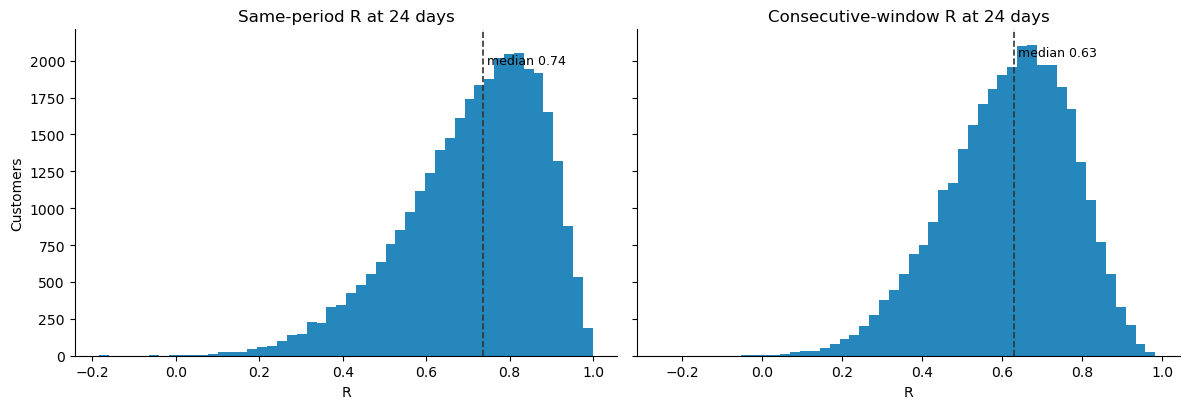

In [8]:
adj_matrix = np.vstack([adjacent_by_customer[L] for L in WINDOW_LENGTHS])
valid = ~np.all(np.isnan(adj_matrix), axis=0)
peak_window = np.full(N_CUST, np.nan)
peak_window[valid] = np.array(WINDOW_LENGTHS)[np.nanargmax(adj_matrix[:, valid], axis=0)]

stability = customers.with_columns(
    pl.Series('pattern_r', interleaved_by_customer[STABILIZATION_DAYS]),
    pl.Series('consecutive_r', adjacent_by_customer[STABILIZATION_DAYS]),
    pl.Series('peak_window_days', peak_window),
)

print('Personal peak window length (share of customers):')
with pl.Config(tbl_hide_dataframe_shape=True):
    print(stability.group_by('peak_window_days').len().sort('peak_window_days')
          .with_columns((pl.col('len') / pl.col('len').sum()).round(3).alias('share')))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title in [(axes[0], 'pattern_r', f'Same-period R at {STABILIZATION_DAYS} days'),
                       (axes[1], 'consecutive_r', f'Consecutive-window R at {STABILIZATION_DAYS} days')]:
    ax.hist(stability[col].drop_nans().drop_nulls(), bins=50, color='#0072B2', alpha=0.85)
    med = stability[col].median()
    ax.axvline(med, color='#333333', linestyle='--', linewidth=1.2)
    ax.text(med, ax.get_ylim()[1] * 0.95, f' median {med:.2f}', fontsize=9, va='top')
    ax.set_title(title)
    ax.set_xlabel('R')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Customers')
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/stabilization_by_customer.png', dpi=150)
plt.show()

## 5. When in the year are patterns least stable?

Removing peers takes out effects that all customers share, but not differences in **timing**. For example, households switch heating or air conditioning on at different dates. The chart shows the median consecutive-window R (at the stabilization length) for each start date through the year. Dips mark periods where many customers' patterns shift relative to their peers.

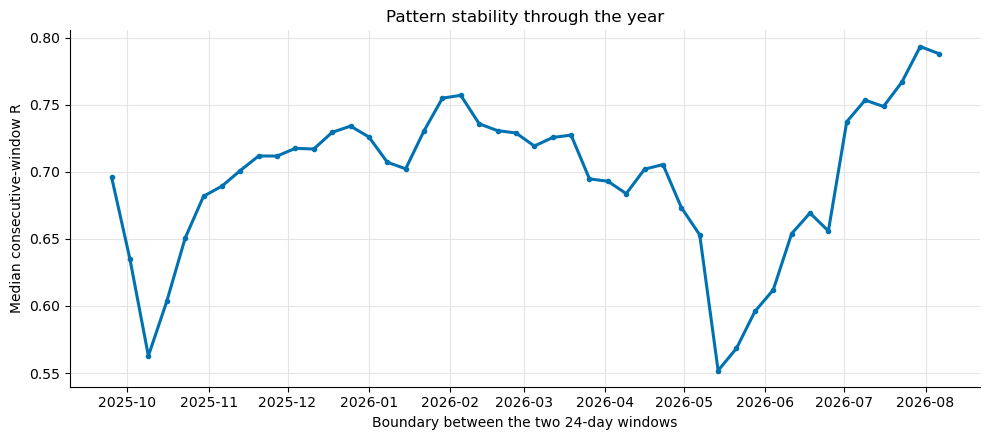

Least stable boundaries:
┌─────────────┬──────────┐
│ change_date ┆ median_r │
│ ---         ┆ ---      │
│ date        ┆ f64      │
╞═════════════╪══════════╡
│ 2026-05-14  ┆ 0.551885 │
│ 2025-10-09  ┆ 0.562795 │
│ 2026-05-21  ┆ 0.568444 │
│ 2026-05-28  ┆ 0.595907 │
│ 2025-10-16  ┆ 0.60343  │
│ 2026-06-04  ┆ 0.612    │
└─────────────┴──────────┘


In [9]:
L = STABILIZATION_DAYS
through_year = []
for a in range(0, N_DAYS - 2 * L + 1, 7):
    block = E[:, a:a + 2 * L]
    r = row_corr(np.nanmean(block[:, :L], axis=1), np.nanmean(block[:, L:], axis=1))
    through_year.append({'change_date': dates[a + L], 'median_r': float(np.nanmedian(r))})
through_year = pl.DataFrame(through_year)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(through_year['change_date'], through_year['median_r'], color='#0072B2', linewidth=2.2, marker='o', markersize=3)
ax.set_xlabel(f'Boundary between the two {L}-day windows')
ax.set_ylabel('Median consecutive-window R')
ax.set_title('Pattern stability through the year')
ax.grid(color='#e5e5e5', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/stability_through_year.png', dpi=150)
plt.show()

with pl.Config(tbl_rows=6, tbl_hide_dataframe_shape=True):
    print('Least stable boundaries:')
    print(through_year.sort('median_r').head(6))

Stability drops around the **seasonal transitions**: when heating comes on in autumn and when cooling starts in late spring and early summer. Households start heating and cooling on different dates and react to the first cold or hot spells differently, so their patterns shift relative to peers even though nothing has been installed.

This matters most for **heat pumps**. A customer whose use jumps relative to peers in October or November may simply have turned their heating on earlier or later than their peers. Notebook 60 should require stronger evidence for changes that start around these transitions, or compare against peers' own heating start.

## 6. Usage level, and a cross-check with a weather model

So far we've looked at the **shape** of the daily pattern. A heat pump mainly changes **how much** is used on cold days, which shape-based R ignores. So we also measure each customer's daily **level**: average residual across all hours of the day.

To check how well weather and seasonality are removed, we compare four ways of turning daily use into a residual:

| Method | Daily residual |
|---|---|
| Raw | Normalized daily use minus the customer's own yearly average |
| Weather model | Normalized daily use minus a per-customer fit on heating degrees (below 55°F), cooling degrees (above 65°F) and weekend |
| Peer-relative | Daily average of the peer-relative residuals above |
| **Hybrid** | Peer-relative residual, then a per-customer fit on the same weather terms, which removes how the customer's weather response *differs* from their peers' |

A good method leaves **less week-to-week variation** in weekly averages (lower SD). It also leaves less **week-to-week correlation**, meaning leftover seasonal drift. The weather terms are fitted on the whole year, a limitation discussed below.

In [10]:
daily_peer = np.nanmean(E, axis=2)                                        # customers x days
daily_raw = np.nanmean(E + P[group_of], axis=2)
daily_raw = daily_raw - np.nanmean(daily_raw, axis=1, keepdims=True)

wx = con.sql('''
    SELECT w.usage_date, AVG(w.temp) AS temp, ANY_VALUE(d.day_type) AS day_type
    FROM weather_features w
    JOIN (SELECT DISTINCT usage_date, day_type FROM ami) d USING (usage_date)
    GROUP BY 1 ORDER BY 1
''').pl()
temp = wx['temp'].to_numpy()
temp = np.where(np.isnan(temp), np.nanmean(temp), temp)
W = np.column_stack([np.ones(N_DAYS), np.maximum(55 - temp, 0), np.maximum(temp - 65, 0),
                     (wx['day_type'] == 'Weekend').to_numpy().astype(float)])


def remove_weather(Y):
    """Per-customer least-squares fit of Y (customers x days) on the weather design W; return residuals."""
    mask = ~np.isnan(Y)
    XtX = np.einsum('dk,dl,cd->ckl', W, W, mask.astype(float))
    XtY = np.einsum('dk,cd->ck', W, np.where(mask, Y, 0))
    beta = np.linalg.solve(XtX + 1e-9 * np.eye(W.shape[1]), XtY[..., None])[..., 0]
    return Y - beta @ W.T


daily_weather = remove_weather(np.nanmean(E + P[group_of], axis=2))
daily_hybrid = remove_weather(daily_peer)


def weekly(A):
    n_weeks = N_DAYS // 7
    return np.nanmean(A[:, :n_weeks * 7].reshape(A.shape[0], n_weeks, 7), axis=2)


def lag1(Wk):
    a, b = Wk[:, :-1], Wk[:, 1:]
    return row_corr(a, b)


comparison = []
for name, A in [('Raw', daily_raw), ('Weather model', daily_weather),
                ('Peer-relative', daily_peer), ('Hybrid (peer + weather)', daily_hybrid)]:
    Wk = weekly(A)
    comparison.append({'method': name,
                       'median_weekly_sd': float(np.nanmedian(np.nanstd(Wk, axis=1))),
                       'median_week_to_week_corr': float(np.nanmedian(lag1(Wk)))})
comparison = pl.DataFrame(comparison).with_columns(pl.selectors.float().round(3))
comparison

method,median_weekly_sd,median_week_to_week_corr
str,f64,f64
"""Raw""",0.354,0.695
"""Weather model""",0.199,0.52
"""Peer-relative""",0.248,0.673
"""Hybrid (peer + weather)""",0.183,0.485


### What the cross-check shows

- **Every method removes a lot of variation** compared with raw use.
- **For level, peer-relative on its own is not the best.** Its weekly residuals stay strongly correlated week to week. Customers whose heating or cooling response differs from their peers' drift slowly above or below them as the seasons change, and that drift could be mistaken for adoption.
- **The hybrid (peer-relative, then a per-customer weather adjustment) leaves the least variation and the least drift.** Peers remove what all customers share (season, holidays, calendar), and the weather terms remove each customer's own extra response to temperature.

**The trade-off for change detection:** here the weather terms are fitted on the full year, so for a customer who installed a heat pump mid-winter, the fit partly absorbs the new heating response. Notebook 60 should fit the weather adjustment on a **reference period before a candidate change** and compare after against it, or compare before and after fits directly, rather than using a full-year fit.

**Conclusion:** use **peer-relative residuals for shape** (good for EV charging blocks and solar dips) and **hybrid residuals for level and temperature response** (needed for heat pumps).

### How much does level normally move?

To set a threshold for "a real change in level", we need each customer's normal variation. For window lengths from 1 to 8 weeks, we compare the average hybrid residual in one window with the next, and take the standard deviation of that difference over start dates. That is the size of a typical shift when nothing has been installed.

In [11]:
level_noise_curve = []
level_noise_by_customer = {}
for L in sorted({7, 14, 21, 28, 35, 42, 56, STABILIZATION_DAYS}):
    diffs = []
    for a in range(0, N_DAYS - 2 * L + 1, 7):
        diffs.append(np.nanmean(daily_hybrid[:, a + L:a + 2 * L], axis=1) - np.nanmean(daily_hybrid[:, a:a + L], axis=1))
    sd = np.nanstd(np.array(diffs), axis=0)
    level_noise_by_customer[L] = sd
    level_noise_curve.append({'window_days': L, 'median_level_shift_sd': float(np.nanmedian(sd)),
                              'p90_level_shift_sd': float(np.nanpercentile(sd, 90))})
level_noise_curve = pl.DataFrame(level_noise_curve).with_columns(pl.selectors.float().round(3))
level_noise_curve

window_days,median_level_shift_sd,p90_level_shift_sd
i64,f64,f64
7,0.185,0.343
14,0.164,0.326
21,0.157,0.329
24,0.154,0.33
28,0.153,0.332
35,0.148,0.33
42,0.143,0.326
56,0.132,0.314


Normal level shifts get smaller as windows get longer, quickly at first and then slowly. Going from 1 to 3 weeks removes most of the noise; going from 4 to 8 weeks helps only a little. Numbers are in units of the customer's own average use, so 0.15 means a shift of 15% of a typical hour's use. The 90th percentile is about twice the median, so some customers are much less steady than others.

For a change in level to stand out, it should be **several times** a customer's normal shift. Notebook 60 will set the exact multiple using simulated changes added to real customers' data. Each customer's own figure is saved so the threshold can adapt: steady customers can be flagged on smaller changes than erratic ones.

## 7. Save the results

**`customer_stability`** (one row per customer):

| Column | Meaning |
|---|---|
| `peer_group` | Peer group (0–15) |
| `pattern_r` | Same-period R at the stabilization length: how measurable the customer's pattern is |
| `consecutive_r` | Consecutive-window R at the stabilization length: normal drift in shape |
| `peak_window_days` | Window length where the customer's own consecutive R is highest (noisy) |
| `level_shift_sd` | SD of shifts in hybrid level between consecutive windows of the stabilization length |
| `stabilization_days` | The overall stabilization length, repeated on every row for convenience |

Together with `customer_peer_groups` and `peer_index`, this is everything notebook 60 needs.

In [12]:
stability = stability.with_columns(
    pl.Series('level_shift_sd', level_noise_by_customer[STABILIZATION_DAYS]),
    pl.lit(STABILIZATION_DAYS).alias('stabilization_days'),
)
con.register('stability_df', stability)
con.execute('CREATE OR REPLACE TABLE customer_stability AS SELECT * FROM stability_df ORDER BY CUSTOMER_NUMBER')

with pl.Config(tbl_hide_dataframe_shape=True):
    print(con.sql('SELECT COUNT(*) AS customers, MEDIAN(pattern_r) AS median_pattern_r, '
                  'MEDIAN(consecutive_r) AS median_consecutive_r, MEDIAN(level_shift_sd) AS median_level_shift_sd '
                  'FROM customer_stability').pl())

┌───────────┬──────────────────┬──────────────────────┬───────────────────────┐
│ customers ┆ median_pattern_r ┆ median_consecutive_r ┆ median_level_shift_sd │
│ ---       ┆ ---              ┆ ---                  ┆ ---                   │
│ i64       ┆ f32              ┆ f32                  ┆ f64                   │
╞═══════════╪══════════════════╪══════════════════════╪═══════════════════════╡
│ 33310     ┆ 0.73606          ┆ 0.628981             ┆ 0.15406               │
└───────────┴──────────────────┴──────────────────────┴───────────────────────┘


## Summary, and rules for notebook 60

- **Stripping shared effects is essential.** Raw usage patterns look similar for everyone. Relative to peers, a customer's pattern is specific to them.
- **Patterns take about the stabilization length (roughly 3–4 weeks) to settle**, with or without weekends included. Shorter windows are dominated by noise; longer ones are blurred by drift. **A new pattern should therefore last at least this long before it is flagged**, and windows of this length should be compared on each side of a candidate change.
- **Changes in the first and last stabilization length of the year can't be confirmed**, because there isn't enough data on both sides. Notebook 60 will report the date range in which changes can be detected.
- **Use peer-relative residuals for shape and hybrid residuals for level and temperature response.** For the hybrid, fit the weather terms on the period *before* a candidate change.
- **Thresholds should depend on the customer.** Each customer's normal level shift and pattern reliability are saved in `customer_stability`.
- **Be cautious around the seasonal transitions** (autumn heating start, late-spring cooling start), when patterns shift naturally relative to peers. This affects heat pumps most.

In [13]:
del E, P, daily_peer, daily_raw, daily_weather, daily_hybrid
con.close()